# Cicero → `epione.tl` — R parity validation

Pipeline-level comparison of the epione port with R **cicero 1.3.9** (Monocle 3 branch,
cole-trapnell-lab/cicero-release@495ef0d), monocle3 1.3.1, glasso 1.11, R 4.3.3, following the
6-section schema of omicverse-rebuildr `NOTEBOOKS.md`. Gates and thresholds are those
pre-registered in `../manifest.yaml` / `../MANIFEST.md` before the port was written.

Fixtures: **F1** Cicero's `cicero_data` (200 cells, hg19 chr18); **F2** E8.5 heart multiome ATAC,
chr19 (16,787 cells × 8,927 peaks); **F3** the same data, whole genome (331,372 peaks), runtime.

## 1. Setup

In [1]:
import os, sys, json, time, subprocess, tempfile
for k in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ.setdefault(k, "8")
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt, yaml
import epione as epi
from epione.tl import _cicero as C
from epione.tl._rrng import RRandom
HERE = Path(".").resolve()                       # tests/parity/cicero/examples
PARITY = HERE.parent                             # tests/parity/cicero
sys.path.insert(0, str(PARITY))
import parity_check as P, parity_utils as U
D = Path(os.environ["EPIONE_CICERO_PARITY_DIR"])  # fixtures/, ref/, results/
manifest = yaml.safe_load((PARITY / "manifest.yaml").read_text())

gates = pd.DataFrame(manifest["outputs"] + manifest["addendum_1_outputs"])[["id", "name", "fixtures", "mode", "class", "threshold"]]
print("upstream:", manifest["upstream"]["name"], manifest["upstream"]["version"], manifest["upstream"]["commit"][:7], "| seed", manifest["seed"])
gates

upstream: cicero 1.3.9 495ef0d | seed 42


,id,name,fixtures,mode,class,threshold
0,1,r_rng_draws,"[F1, F2]",rrng,deterministic-strict,exact
1,2,knn_index,"[F1, F2]",-,deterministic-strict,exact
2,3,cicero_cds_matrix,"[F1, F2]",injected,deterministic-standard,0.0
3,4,glasso_unit,"[F1, F2, synthetic]",same S and rho,deterministic-standard,1.0e-8; zero pattern exact
4,5,distance_parameters,"[F1, F2]",injected,deterministic-bounded,0.000001
5,6,mean_distance_parameter,"[F1, F2]",rrng,deterministic-bounded,0.000001
6,7,window_status,"[F1, F2]",rrng,deterministic-strict,exact
7,8,coaccess_pairs,"[F1, F2]",rrng,deterministic-strict,exact
8,9,coaccess_values,"[F1, F2]",rrng,deterministic-standard,0.0
9,10,coaccess_values_corr,"[F1, F2]",rrng,ordinal,0.9999


## 2. R reference run

The full reference dumps (all intermediates, glasso probes, per-window distance parameters,
CCANs for five seeds) were produced by `../r_reference_driver.R` in `full` mode and are read from
`$EPIONE_CICERO_PARITY_DIR/ref`. Here R is re-run on F1 in `light` mode to show the call and
check that the stored dump is reproducible.

In [2]:
rs = Path(os.environ["R_TEST_ENV"]) / "bin" / "Rscript"
tmp = Path(tempfile.mkdtemp())
t0 = time.perf_counter()
r = subprocess.run([str(rs), str(PARITY / "r_reference_driver.R"), str(D / "fixtures/F1"), str(tmp), "42", "light"],
                   capture_output=True, text=True)
r_wall = time.perf_counter() - t0
print((tmp / "versions.txt").read_text())
print(f"R wall-clock (read + make_cicero_cds + run_cicero steps): {r_wall:.1f} s")
same = all((tmp / f).read_bytes() == (D / "ref/F1_seed42" / f).read_bytes()
           for f in ("conns_peak1.txt", "conns_peak2.txt", "conns_coaccess.f64", "agg_cells.txt"))
print("re-run identical to the stored F1 dump:", same)

R version 4.3.3 (2024-02-29)
cicero 1.3.9
monocle3 1.3.1
glasso 1.11
FNN 1.1.4.1
igraph 2.1.4
seed 42
mode light

R wall-clock (read + make_cicero_cds + run_cicero steps): 139.8 s
re-run identical to the stored F1 dump: True


## 3. Python candidate run

`parity_check.main` runs the port on a fixture (seed 42, R's RNG emulated) and evaluates every
gate against the R dump; `parity_utils.main` covers the exported utilities (gates 19–24).

In [3]:
t0 = time.perf_counter(); res1 = P.main([str(D / "fixtures/F1"), str(D / "ref/F1_seed42"), str(tmp / "F1.json"), "--threads", "8"]); w1 = time.perf_counter() - t0
t0 = time.perf_counter(); res2 = P.main([str(D / "fixtures/F2"), str(D / "ref/F2_seed42"), str(tmp / "F2.json"), "--threads", "8"]); w2 = time.perf_counter() - t0
resu = U.main([str(D / "ref/F1_utils"), str(tmp / "utils.json")])
print(f"parity harness wall-clock: F1 {w1:.0f} s, F2 {w2:.0f} s (includes all gate computations)")

Overlap QC metrics:
Cells per bin: 50
Maximum shared cells bin-bin: 44
Mean shared cells bin-bin: 11.17
Median shared cells bin-bin: 0.5


/scratch/users/steorra/analysis/26_dynode-project/cicero_port/epione/epione/tl/_cicero.py:328: UserWarning: On average, more than 10% of cells are shared between paired bins.
  warnings.warn("On average, more than 10% of cells are shared between paired bins.")


{
"4": true,
"2": true,
"1a_bins": null,
"3": true,
"5": true,
"1b_windows": null,
"1": true,
"6": true,
"7": true,
"8": true,
"9": true,
"10": true,
"11": true,
"13": true,
"12": true,
"16": true,
"17": true,
"14": true,
"15": true
}
ALL PASS


Overlap QC metrics:
Cells per bin: 50
Maximum shared cells bin-bin: 44
Mean shared cells bin-bin: 0.152754686249939
Median shared cells bin-bin: 0


{
"4": true,
"2": true,
"1a_bins": null,
"3": true,
"5": true,
"1b_windows": null,
"1": true,
"6": true,
"7": true,
"8": true,
"9": true,
"10": true,
"11": true,
"13": true,
"12": true,
"16": true,
"17": true
}
ALL PASS


{
 "gates": {
  "19": {
   "peak_order": true,
   "cell_order": true,
   "matrix_binary": true,
   "matrix_counts": true,
   "var_coords": true,
   "num_cells_expressed": true,
   "num_genes_expressed": true,
   "pass": true
  },
  "20": {
   "1000": {
    "names": true,
    "cells": true,
    "matrix": true,
    "n_bins": 4984
   },
   "10000": {
    "names": true,
    "cells": true,
    "matrix": true,
    "n_bins": 1690
   },
   "pass": true
  },
  "21": {
   "names_rows": true,
   "names_cols": true,
   "max_abs_err": 0.0,
   "size_factor_max_abs_err": 1.1102230246251565e-16,
   "num_genes_expressed": true,
   "n": true,
   "pass": true
  },
  "22": {
   "0": {
    "n": 10866,
    "n_true_r": 100,
    "n_true_py": 100,
    "identical": true
   },
   "1000": {
    "n": 10866,
    "n_true_r": 365,
    "n_true_py": 365,
    "identical": true
   },
   "pass": true
  },
  "23": {
   "0": {
    "single": true,
    "multi": true,
    "n_single": 126,
    "n_multi": 11
   },
   "500": {
  

## 4. Per-output parity

### 4.1 Aggregation, RNG and kNN (gates 1–3, deterministic)

The bins are chosen by R's `sample()`; with `RRandom` the port draws the same numbers, so the
same seed cells are accepted in the same order. Gate 3 feeds R's bins to the port ("injected")
and compares the size-factor-normalised matrix.

In [4]:
rows = []
for fx, res in (("F1", res1), ("F2", res2)):
    g = res["gates"]
    rows.append({"fixture": fx, "bins R": g["1a_bins"]["n_bins_r"], "bins Py": g["1a_bins"]["n_bins_py"],
                 "bins identical": g["1a_bins"]["identical"], "sampled windows identical": g["1b_windows"]["identical"],
                 "kNN sets differing": g["2"]["cells_with_different_neighbour_set"],
                 "matrix max abs err": g["3"]["max_abs_err_matrix"], "size factor max abs err": g["3"]["max_abs_err_size_factor_final"]})
pd.DataFrame(rows)

,fixture,bins R,bins Py,bins identical,sampled windows identical,kNN sets differing,matrix max abs err,size factor max abs err
0,F1,25,25,True,True,0,0.0,0.0
1,F2,3235,3235,True,True,0,0.0,0.0


### 4.2 Graphical lasso on identical inputs (gate 4, deterministic)

In [5]:
pd.DataFrame([{"fixture": fx, "set": k, **v} for fx, res in (("F1", res1), ("F2", res2))
              for k, v in res["gates"]["4"].items() if isinstance(v, dict)])

,fixture,set,n,max_abs_err_w,max_abs_err_wi,zero_pattern_mismatch,niter_mismatch
0,F1,probe,40,2.664535e-15,5.404218e-09,0,0
1,F1,syn,4,0.000000e+00,0.000000e+00,0,0
2,F2,probe,40,4.440892e-15,9.992007e-16,0,0
3,F2,syn,4,0.000000e+00,0.000000e+00,0,0


### 4.3 Distance parameters (gates 5–7)

Per sampled window (R's window sequence injected) and the mean that `run_cicero` uses.

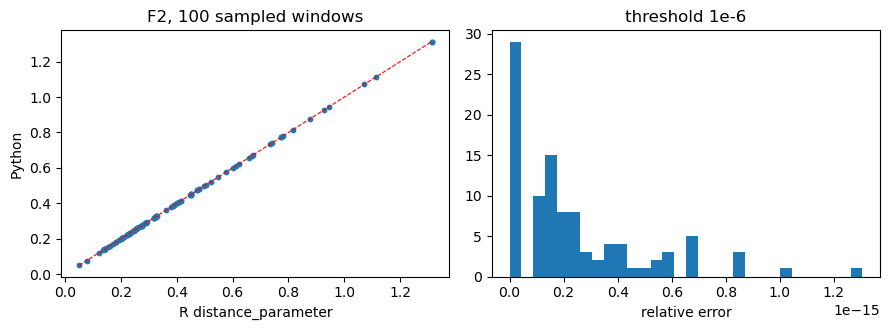

F1 gate 5 max rel err 2.6e-15 | gate 6 mean R 0.6404942304943019 Py 0.6404942304943019 | gate 7 window status identical: True
F2 gate 5 max rel err 1.3e-15 | gate 6 mean R 0.4013476662018633 Py 0.4013476662018633 | gate 7 window status identical: True


In [6]:
ad2, co2, g2 = P.read_fixture(D / "fixtures/F2")
sw = pd.read_csv(D / "ref/F2_seed42/sampled_windows.tsv", sep="\t")
r_dp = sw.loc[sw.status == "ok", "dp"].to_numpy(float)
cds2 = C.make_cicero_cds(ad2, co2, random_state=42, silent=True)
py_dp = C.estimate_distance_parameter(cds2, genomic_coords=g2, sample_windows=sw["win"].tolist(), n_jobs=8)
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].scatter(r_dp, py_dp, s=10); ax[0].plot([r_dp.min(), r_dp.max()], [r_dp.min(), r_dp.max()], "r--", lw=0.8)
ax[0].set(xlabel="R distance_parameter", ylabel="Python", title="F2, 100 sampled windows")
ax[1].hist(np.abs(py_dp - r_dp) / r_dp, bins=30); ax[1].set(xlabel="relative error", title="threshold 1e-6")
plt.tight_layout(); plt.show()
for fx, res in (("F1", res1), ("F2", res2)):
    print(fx, "gate 5 max rel err %.1e | gate 6 mean R %r Py %r | gate 7 window status identical: %s"
          % (res["gates"]["5"]["max_rel_err"], res["gates"]["6"]["mean_r"], res["gates"]["6"]["mean_py"], res["gates"]["7"]["status_identical"]))

### 4.4 Co-accessibility (gates 8–12)

Same set of `(Peak1, Peak2)` rows (also the same row order), same `NA` pattern, and values within
rounding of R (deterministic class, threshold 1e-8; ordinal Pearson/Spearman ≥ 0.9999; Jaccard
of pairs > 0.25 ≥ 0.999).

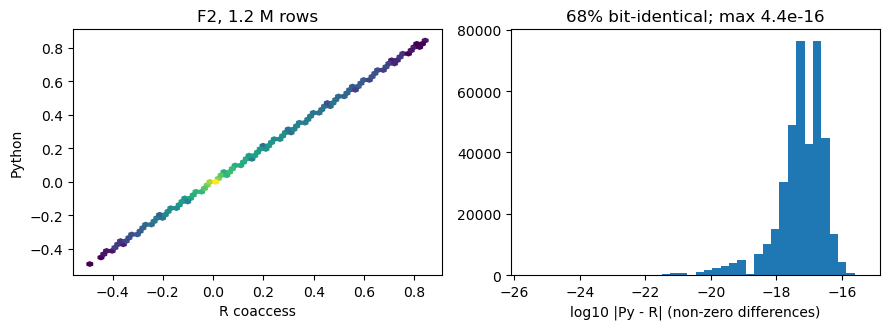

,fixture,g8,g9,g10,g11,g12,g13,max abs err,Pearson,Jaccard>0.25,same row order
0,F1,True,True,True,True,True,True,8.049117e-16,1.0,1.0,True
1,F2,True,True,True,True,True,True,4.440892e-16,1.0,1.0,True


In [7]:
conns2 = C.run_cicero(cds2, g2, random_state=42, n_jobs=8, silent=True)
rc2 = P.read_ref_conns(D / "ref/F2_seed42")
ok = ~np.isnan(rc2["coaccess"].to_numpy())
x, y = rc2["coaccess"].to_numpy()[ok], conns2["coaccess"].to_numpy()[ok]     # same row order as R
fig, ax = plt.subplots(1, 2, figsize=(9, 3.4))
ax[0].hexbin(x, y, gridsize=60, bins="log", cmap="viridis"); ax[0].set(xlabel="R coaccess", ylabel="Python", title="F2, 1.2 M rows")
d = np.abs(x - y); ax[1].hist(np.log10(d[d > 0]), bins=40)
ax[1].set(xlabel="log10 |Py - R| (non-zero differences)", title=f"{(d == 0).mean():.0%} bit-identical; max {d.max():.1e}")
plt.tight_layout(); plt.show()
pd.DataFrame([{"fixture": fx, **{f"g{k}": res["gates"][k]["pass"] for k in ("8", "9", "10", "11", "12", "13")},
               "max abs err": res["gates"]["9"]["max_abs_err"], "Pearson": res["gates"]["10"]["pearson"],
               "Jaccard>0.25": res["gates"]["11"]["jaccard"], "same row order": res["gates"]["8"]["same_row_order"]}
              for fx, res in (("F1", res1), ("F2", res2))])

### 4.5 Gene activity (gates 14–15, F1)

In [8]:
pd.DataFrame([{"gate": k, **res1["gates"][k]} for k in ("14", "15")])

,gate,annotation_gene_column_identical,genes_py,genes_r,max_abs_err,pass,max_rel_err,same_genes
0,14,True,602,602,8.881784e-16,True,NaN,NaN
1,15,NaN,602,602,NaN,True,6.661338e-16,True


### 4.6 CCANs (gates 16–17, clustering)

Louvain is randomised. The port runs igraph's Louvain (C core 0.10, as in R igraph 2.1.4) on R's
random stream, so with the same seed the CCAN table is identical to R's (checked for seeds
{42, 2017, 7, 11, 23}); the gate (ARI against R at R's cutoff, seed 42) is then 1. The R-vs-R
agreement across seeds is shown as the noise floor of the pre-registered rule.

F1 identical CCAN table, same seed: {'42': True, '2017': True, '7': True, '11': True, '23': True}
F1 ARI Py(seed 42) vs R per R seed: {'42': 1.0, '2017': 0.935, '7': 0.956, '11': 0.952, '23': 0.935} | R vs R median 0.964 min 0.935 | threshold 0.950 -> PASS
   cutoff Py 0.46, R 0.46 (R range over seeds [0.46, 0.46]) -> PASS
F2 identical CCAN table, same seed: {'42': True, '2017': True, '7': True, '11': True, '23': True}
F2 ARI Py(seed 42) vs R per R seed: {'42': 1.0, '2017': 1.0, '7': 0.995, '11': 0.974, '23': 1.0} | R vs R median 0.995 min 0.969 | threshold 0.950 -> PASS
   cutoff Py 0.27, R 0.27 (R range over seeds [0.27, 0.29]) -> PASS


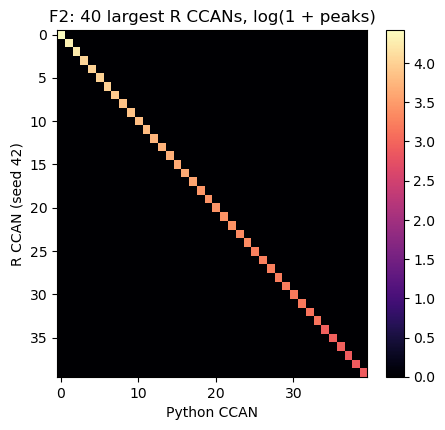

In [9]:
from sklearn.metrics import adjusted_rand_score, confusion_matrix
for fx, res in (("F1", res1), ("F2", res2)):
    g = res["gates"]["16"]
    print(fx, "identical CCAN table, same seed:", g["identical_tables_same_seed"])
    print(fx, "ARI Py(seed 42) vs R per R seed:", {k: round(v, 3) for k, v in g["ari_py_vs_r_seed"].items()},
          "| R vs R median %.3f min %.3f | threshold %.3f -> %s" % (g["r_vs_r_median"], g["r_vs_r_min"], g["threshold_applied"], "PASS" if g["pass"] else "FAIL"))
    print("   cutoff Py %.2f, R %.2f (R range over seeds %s) -> %s" % (res["gates"]["17"]["cutoff_py"], res["gates"]["17"]["cutoff_r"], res["gates"]["17"]["r_range"], "PASS" if res["gates"]["17"]["pass"] else "FAIL"))
cut = float(pd.read_csv(D / "ref/F2_seed42/ccan_cutoffs.tsv", sep="\t")["cutoff"].iloc[0])
py = C.generate_ccans(rc2, coaccess_cutoff_override=cut, random_state=42, silent=True)
rr = pd.read_csv(D / "ref/F2_seed42/ccan_fixedcut_seed42.tsv", sep="\t")
uni = sorted(set(py.Peak) | set(rr.Peak))
lp = pd.Series(py.CCAN.values, index=py.Peak).reindex(uni).fillna(0).astype(int)
lr = pd.Series(rr.CCAN.values, index=rr.Peak).reindex(uni).fillna(0).astype(int)
ct = pd.crosstab(lr, lp)
order_r = ct.max(1).sort_values(ascending=False).index[:40]; order_p = ct.loc[order_r].idxmax(1).unique()
plt.figure(figsize=(5, 4.5)); plt.imshow(np.log1p(ct.loc[order_r, order_p].to_numpy()), cmap="magma", aspect="auto")
plt.xlabel("Python CCAN"); plt.ylabel("R CCAN (seed 42)"); plt.title("F2: 40 largest R CCANs, log(1 + peaks)"); plt.colorbar(); plt.show()

### 4.7 Free-running numpy RNG (gate 18, stochastic)

With `rng="numpy"` the bins and windows are drawn by numpy instead of R's generator, so the port
can only agree with R in distribution. Pre-registered rule: Pearson and Jaccard(> 0.25) of
Python(numpy, seed 42) vs R(seed 42) must reach the median R(seed 42)-vs-R(seed s) agreement over
s ∈ {2017, 7, 11, 23} minus 0.02.

In [10]:
g18 = subprocess.run([sys.executable, str(PARITY / "gate18_numpy_rng.py"), str(D / "fixtures/F2"), str(D / "ref"),
                      str(tmp / "gate18.json"), "8"], capture_output=True, text=True, cwd=PARITY)
res18 = json.loads((tmp / "gate18.json").read_text())
pd.DataFrame({**{"Py(numpy) vs R42": res18["py_numpy_vs_r42"]}, **{f"R42 vs R{k}": v for k, v in res18["r42_vs_r_seed"].items()}}).T.assign(
    threshold_pearson=res18["threshold_pearson"], threshold_jaccard=res18["threshold_jaccard"])

,pearson,jaccard,threshold_pearson,threshold_jaccard
Py(numpy) vs R42,0.991260,0.858209,0.97157,0.847786
R42 vs R2017,0.991634,0.865990,0.97157,0.847786
R42 vs R7,0.991505,0.869582,0.97157,0.847786
R42 vs R11,0.992595,0.871362,0.97157,0.847786
R42 vs R23,0.989108,0.832581,0.97157,0.847786


### 4.8 Exported utilities (gates 19–24, F1)

In [11]:
pd.DataFrame([{"gate": k, "pass": v["pass"]} for k, v in resu["gates"].items()] + [{"gate": "find_overlapping_ccans (info)", "pass": resu["informational"].get("find_overlapping_ccans_identical")}])

,gate,pass
0,19,True
1,20,True
2,21,True
3,22,True
4,23,True
5,24,True
6,find_overlapping_ccans (info),True


## 5. Wall-clock comparison

R runs single-threaded (Cicero calls `mclapply(mc.cores = 1)`). Python: 1 thread and 8 threads
(`n_jobs`, identical output). Same node; the allocation was shared with other jobs, so expect
±25 % noise. "run_cicero" = `estimate_distance_parameter` + `generate_cicero_models` +
`assemble_connections`.

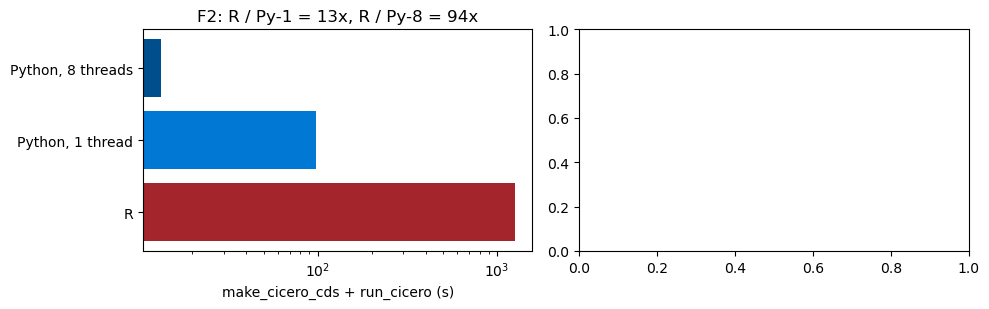

,fixture,implementation,make_cicero_cds_s,run_cicero_s
0,F2,R,166.055000,1088.349000
1,F2,"Python, 1 thread",5.973898,91.619892
2,F2,"Python, 8 threads",2.273437,11.076702


In [12]:
def rt(fx):
    t = pd.read_csv(D / f"ref/{fx}_seed42/timings.tsv", sep="\t").set_index("step")["seconds"]
    return t.get("make_cicero_cds"), t.get("run_cicero_steps_total")
def pt(name):
    f = D / f"results/{name}.timings.json"
    if not f.exists(): return (np.nan, np.nan)
    t = json.loads(f.read_text()); return t["make_cicero_cds"], t["run_cicero_steps_total"]
rows = []
for fx, n1, n8 in (("F2", "py_F2_nj1", "py_F2_nj8"), ("F3", "py_F3_nj1", "py_F3_nj8")):
    if not (D / f"ref/{fx}_seed42/timings.tsv").exists(): continue
    for who, (m, r) in (("R", rt(fx)), ("Python, 1 thread", pt(n1)), ("Python, 8 threads", pt(n8))):
        rows.append({"fixture": fx, "implementation": who, "make_cicero_cds_s": m, "run_cicero_s": r})
tim = pd.DataFrame(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for a, fx in zip(ax, ("F2", "F3")):
    sub = tim[tim.fixture == fx]
    if sub.empty: continue
    tot = sub.make_cicero_cds_s + sub.run_cicero_s
    a.barh(sub.implementation, tot, color=["#a4262c", "#0078d4", "#004e8c"][:len(sub)])
    a.set_xscale("log"); a.set_xlabel("make_cicero_cds + run_cicero (s)")
    a.set_title(f"{fx}: R / Py-1 = {tot.iloc[0] / tot.iloc[1]:.0f}x, R / Py-8 = {tot.iloc[0] / tot.iloc[2]:.0f}x" if len(sub) == 3 else fx)
plt.tight_layout(); plt.show()
tim

## 6. Verdict

In [13]:
rows = []
def thr(g):
    for o in manifest["outputs"] + manifest["addendum_1_outputs"]:
        if str(o["id"]) == g: return o["threshold"]
for fx, res in (("F1", res1), ("F2", res2)):
    for g, v in res["gates"].items():
        if "pass" in v and g[0].isdigit() and g.isdigit():
            rows.append({"fixture": fx, "gate": int(g), "threshold": thr(g), "pass": v["pass"]})
for g, v in resu["gates"].items():
    rows.append({"fixture": "F1", "gate": int(g), "threshold": thr(g), "pass": v["pass"]})
rows.append({"fixture": "F2", "gate": 18, "threshold": thr("18"), "pass": res18["pass"]})
f3 = D / "results/F3_compare.json"
if f3.exists():
    print("F3 (genome, informational):", json.loads(f3.read_text()))
ver = pd.DataFrame(rows).sort_values(["gate", "fixture"]).reset_index(drop=True)
display(ver.pivot_table(index="gate", columns="fixture", values="pass", aggfunc="first"))
failed = ver[~ver["pass"]]
print("PASS — all outputs cleared the pre-registered gate" if failed.empty else
      "FAIL — gates %s; see RECONSTRUCTION_REPORT.md §3 (stochastic Louvain gate)" % sorted(set(failed.gate)))

fixture,F1,F2
gate,,
1,True,True
2,True,True
3,True,True
4,True,True
5,True,True
6,True,True
7,True,True
8,True,True
9,True,True


PASS — all outputs cleared the pre-registered gate
